In [17]:
import pandas as pd
from google.colab import files

data_path = "/content/drive/MyDrive/PorifolioProjects/PersonalProjects/AI Engineer Projects/E-commerce_Delivery_Shipping_Data_2026.csv"

df = pd.read_csv(data_path)
display(df)

target = "actual_delivery_days"

features_num = [
    'product_weight_kg',
    'order_value_usd',
    'distance_km',
    'promised_delivery_days',
    'shipping_cost_usd',
    'warehouse_processing_hours'
]

features_cat = [
    'customer_segment',
    'product_category',
    'shipping_method',
    'carrier',
    'package_size',
    'order_priority',
    'weather_condition'

]

print(f"Dataset loaded with {df.shape[0]} rows and {df.shape[1]} columns")



,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.1,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.9,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.5,Delivered
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,...,Large,Debit Card,Normal,Snow,3,No,NaN,1,12.6,In Transit
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,...,Small,Credit Card,Normal,Storm,2,No,NaN,1,24.9,Delivered
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,ORD-049996,2026-09-05,CUS-004163,Small Business,Leipzig,Germany,WH-001,New York,Electronics,0.86,...,Medium,Digital Wallet,High,Cloudy,4,No,NaN,2,9.1,Delivered
49996,ORD-049997,2026-12-07,CUS-004322,Consumer,London,United Kingdom,WH-005,London,Toys,0.27,...,Small,Cash on Delivery,Normal,Cloudy,4,No,NaN,1,8.9,Delivered
49997,ORD-049998,2026-11-14,CUS-000699,Enterprise,San Diego,United States,WH-001,New York,Automotive,7.76,...,Oversized,Credit Card,Low,Clear,3,Yes,Late Delivery,1,5.5,Delivered
49998,ORD-049999,2026-09-02,CUS-004696,Consumer,London,United Kingdom,WH-007,Paris,Books,1.10,...,Medium,PayPal,Low,Snow,3,No,NaN,1,45.4,Delivered


Dataset loaded with 50000 rows and 30 columns


In [18]:
X_raw = df[features_num + features_cat].copy()
y = df[target]

X = pd.get_dummies(X_raw, columns=features_cat, drop_first=True)
print(f"Dimension of the encoded feature matrix: {X.shape}")

Dimension of the encoded feature matrix: (50000, 42)


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.20, random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print("Treinamento concluído com sucesso!")



Treinamento concluído com sucesso!


--- Model Performance ---
MAE (Mean Absolute Error): 0.785 days
RMSE (Root mean Squared Error): 1.051 days
R² Score: 0.949


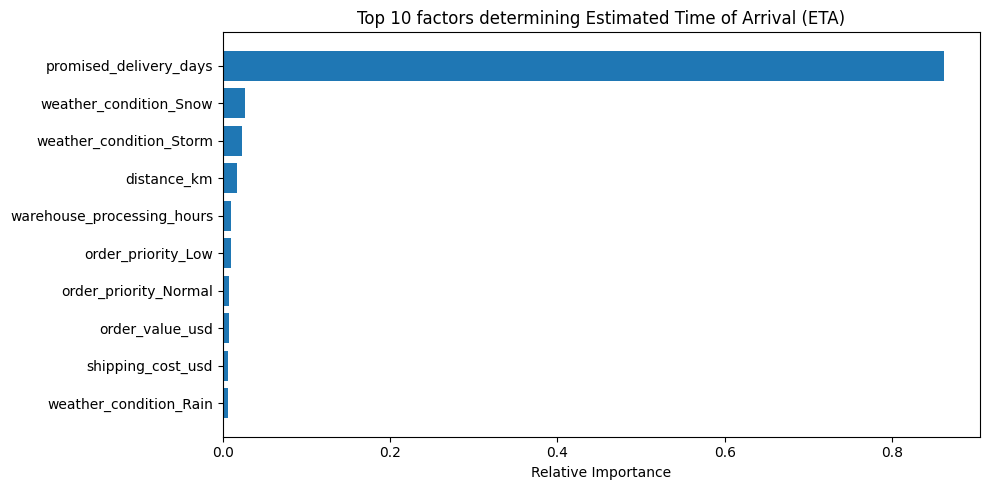

In [21]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

prediction = model.predict(X_test)

mae = mean_absolute_error(y_test, prediction)
rmse = root_mean_squared_error(y_test, prediction)
r2 = r2_score(y_test, prediction)

print("--- Model Performance ---")
print(f"MAE (Mean Absolute Error): {mae:.3f} days")
print(f"RMSE (Root mean Squared Error): {rmse:.3f} days")
print(f"R² Score: {r2:.3f}")

importances = model.feature_importances_
indices = np.argsort(importances)[-10:]

plt.figure(figsize=(10, 5))
plt.title("Top 10 factors determining Estimated Time of Arrival (ETA)")
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()


In [22]:
import joblib

joblib.dump(model, 'logistics_eta_random_forest.joblib')
joblib.dump(X.columns.tolist(), 'model_features.joblib')
print("Data model and schema saved successfully")

Data model and schema saved successfully


In [23]:
%%writefile requirements.txt
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.3.0
matplotlib>=3.7.0
openpyxl>=3.1.0
joblib>=1.3.0

Writing requirements.txt
